# Рынок вакансий аналитиков: что требуют и сколько платят

**Вопрос.** Я перехожу в аналитику и хочу понять по реальным данным, а не по рекламе курсов:
1. Каких аналитиков ищут и сколько им платят в Москве и регионах?
2. Какие навыки упоминают чаще всего и есть ли за них надбавка к зарплате?
3. Сколько вакансий доступно без опыта или с опытом до года?

**Данные.** Настоящие вакансии с портала «Работа России» через его [открытый API](https://opendata.trudvsem.ru/). Выгрузка 21.10.2026, поиск по слову «аналитик» по всей стране, 1 649 вакансий. API hh.ru с 2026 года закрыт для анонимного доступа, поэтому взят государственный портал.

> **Важное ограничение.** На «Работе России» больше госсектора, банков и регионального бизнеса, чем на hh.ru, а IT-компании представлены слабее. Поэтому абсолютные зарплаты здесь ниже рыночных для IT. Корректнее сравнивать группы между собой (роли, навыки, регионы), чем переносить цифры на весь рынок.

In [1]:
import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.max_columns", 20); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}".replace(",", " "))
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e3",
    "axes.axisbelow": True, "axes.edgecolor": "#9a9993", "figure.facecolor": "white",
})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9993"
thous = mticker.FuncFormatter(lambda v, _: f"{v/1000:.0f} тыс")
rng = np.random.default_rng(7)

raw = pd.read_csv("data/vacancies.tsv", sep="\t", encoding="utf-8-sig", dtype=str)
print(f"Строк: {len(raw)}, уникальных вакансий: {raw.id.nunique()}")
raw.head(3)

Строк: 1649, уникальных вакансий: 1648


,id,region,company,job_name,salary_min,salary_max,schedule,employment,experience_years,education,category,created,workplace_type,skill_flags
0,82bfaa28-f6c3-11f0-ba7d-9959eb3311ba,Нижегородская область,"АО КОМБАНК ""АРЗАМАС""",Аналитик,27500,27500,Полный рабочий день,Полная занятость,3,Высшее образование — бакалавриат,"Банки, кредит, страхование, пенсионное обеспеч...",2026-01-21,[object Object],NaN
1,eacf27d8-7eae-11f1-baa9-e58b42ebc806,Город Москва,"ООО ""НИЛЬСЕН ДЭЙТА ФЭКТОРИ""",Маркетолог-аналитик,120000,180000,Полный рабочий день,NaN,4,Высшее образование — бакалавриат,"Информационные технологии, телекоммуникации, с...",2026-07-13,[object Object],excel
2,5340ae58-6aec-11f1-b7e2-61dd9c2afed4,Белгородская область,"ООО""ДЕЛОВЫЕ ЛИНИИ""",Аналитик,37000,37000,Полный рабочий день,NaN,3,Высшее образование — бакалавриат,"Транспорт, автобизнес, логистика, склад, ВЭД",2026-06-18,[object Object],excel


## 1. Очистка: поиск по слову «аналитик» возвращает много лишнего

Полнотекстовый поиск портала находит слово в любом месте вакансии, поэтому в выгрузке оказались фармацевты, программисты и бухгалтеры. Оставляю вакансии, где «аналитик» есть **в названии должности**, и убираю лабораторные профессии (химик-аналитик, провизор-аналитик): к анализу данных они отношения не имеют.

In [2]:
d = raw.drop_duplicates("id").copy()
title = d.job_name.str.lower()
is_analyst = title.str.contains("аналит")
is_lab = title.str.contains("хими|провиз|фармац|лаборан|биолог|эколог|медиц|врач|геолог")
print("Топ-10 должностей во всей выгрузке:")
print(d.job_name.value_counts().head(10).to_string())

steps = pd.DataFrame([
    ("вся выгрузка", len(d)),
    ("«аналитик» в названии должности", is_analyst.sum()),
    ("минус лабораторные профессии", (is_analyst & ~is_lab).sum()),
], columns=["шаг", "вакансий"])
a = d[is_analyst & ~is_lab].copy()
steps

Топ-10 должностей во всей выгрузке:
job_name
Аналитик                                     62
Системный аналитик                           62
Фармацевт                                    60
Ведущий аналитик                             40
Программист                                  35
Химик-аналитик                               23
Специалист по аналитике и ценообразованию    23
Маркетолог-аналитик                          21
Инженер-программист                          21
Экономист                                    18


,шаг,вакансий
0,вся выгрузка,1648
1,«аналитик» в названии должности,640
2,минус лабораторные профессии,587


Дальше привожу типы и проверяю даты: портал хранит и старые вакансии, если работодатель их не закрыл.

In [3]:
a["created"] = pd.to_datetime(a.created)
a["smin"] = pd.to_numeric(a.salary_min, errors="coerce")
a["smax"] = pd.to_numeric(a.salary_max, errors="coerce")
a["exp"] = pd.to_numeric(a.experience_years.str.extract(r"(\d+)")[0], errors="coerce")
print("Год публикации:", a.created.dt.year.value_counts().sort_index().to_dict())

a = a[a.created >= "2025-10-21"].copy()       # только вакансии за последние 12 месяцев
# зарплата: середина вилки, если указаны обе границы, иначе та, что есть
a["salary"] = a[["smin", "smax"]].mean(axis=1)
bad = (a.salary < 20000) | (a.salary > 500000)
print(f"Вакансий за 12 месяцев: {len(a)}; без зарплаты: {a.salary.isna().sum()}; "
      f"зарплата вне 20–500 тыс. (почасовые и опечатки): {bad.sum()}")
a.loc[bad, "salary"] = np.nan
a["moscow"] = np.where(a.region.isin(["Город Москва", "Московская область"]), "Москва и область", "Регионы")
a["remote"] = a.employment.fillna("").str.contains("Дистанц")

Год публикации: {2019: 1, 2022: 3, 2023: 5, 2024: 11, 2025: 62, 2026: 505}
Вакансий за 12 месяцев: 528; без зарплаты: 11; зарплата вне 20–500 тыс. (почасовые и опечатки): 1


## 2. Классификация ролей

В названиях должностей нет единого стандарта: «Аналитик», «Ведущий аналитик», «Аналитик-специалист». Делю на группы по ключевым словам в названии. Если в названии нет подсказки, смотрю на навыки в тексте вакансии (SQL, Python, BI → аналитик данных; 1С → аналитик 1С).

In [4]:
flags = a.skill_flags.fillna("")
for k in ["sql", "python", "excel", "bi", "stat", "c1", "mp", "bpmn", "ml"]:
    a[k] = flags.str.split("|").map(lambda f, k=k: k in f)

def role(row):
    s = row.job_name.lower()
    if re.search(r"данн|data|\bbi\b|bi-|отчетн|отчётн|продукт", s): return "Аналитик данных / BI"
    if re.search(r"систем", s): return "Системный аналитик"
    if re.search(r"бизнес|процесс", s): return "Бизнес-аналитик"
    if re.search(r"финанс|эконом|кредит|риск|инвест|банк|тариф|цен|аудит", s): return "Финансовый аналитик"
    if re.search(r"маркет|продаж|коммерч|закуп|ассортимент|категор|логист|склад", s): return "Аналитик продаж, закупок, логистики"
    if re.search(r"1с|1c", s) or row.c1: return "Аналитик 1С"
    if row.sql or row.python or row.bi: return "Аналитик данных / BI"
    return "Аналитик (без уточнения)"
a["role"] = a.apply(role, axis=1)
a.role.value_counts().rename("вакансий").to_frame()

,вакансий
role,
Аналитик (без уточнения),145
Аналитик 1С,75
Финансовый аналитик,72
Аналитик данных / BI,69
Системный аналитик,66
Бизнес-аналитик,63
"Аналитик продаж, закупок, логистики",38


## 3. Сколько платят разным аналитикам

Зарплаты распределены неравномерно, поэтому смотрю на **медиану**, а не на среднее. Для групп с небольшим числом вакансий считаю 95% доверительный интервал медианы бутстрепом: так видно, где разница между группами надёжная, а где это шум маленькой выборки.

In [5]:
def boot_median_ci(x, n=5000):
    x = np.asarray(x.dropna())
    if len(x) < 5: return (np.nan, np.nan)
    meds = np.median(rng.choice(x, (n, len(x))), axis=1)
    return np.percentile(meds, [2.5, 97.5])

def salary_table(df, by):
    rows = []
    for g, part in df.groupby(by):
        s = part.salary.dropna()
        lo, hi = boot_median_ci(s)
        rows.append({by: g, "вакансий": len(part), "с зарплатой": len(s), "медиана, ₽": s.median(),
                     "95% ДИ от": lo, "95% ДИ до": hi, "25-й перцентиль": s.quantile(.25), "75-й перцентиль": s.quantile(.75)})
    return pd.DataFrame(rows).sort_values("медиана, ₽", ascending=False).reset_index(drop=True)

roles = salary_table(a, "role")
roles

,role,вакансий,с зарплатой,"медиана, ₽",95% ДИ от,95% ДИ до,25-й перцентиль,75-й перцентиль
0,Аналитик данных / BI,69,62,117 100.0,97 500.0,122 500.0,80 375.0,150 000.0
1,Системный аналитик,66,65,102 500.0,95 000.0,120 000.0,74 500.0,162 101.0
2,Бизнес-аналитик,63,62,93 350.0,82 500.0,108 750.0,70 144.8,140 000.0
3,"Аналитик продаж, закупок, логистики",38,38,60 838.5,41 600.0,74 625.0,36 700.0,82 250.0
4,Финансовый аналитик,72,70,57 000.0,49 999.0,79 250.0,35 250.0,101 500.0
5,Аналитик (без уточнения),145,144,50 306.5,45 250.0,56 000.0,35 725.9,77 000.0
6,Аналитик 1С,75,75,41 000.0,35 000.0,50 000.0,34 000.0,75 000.0


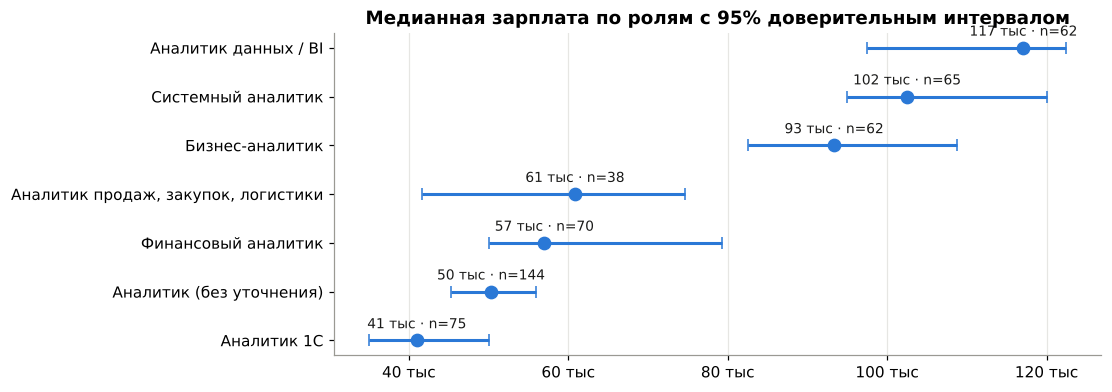

In [6]:
r = roles[roles["с зарплатой"] >= 10].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(r))
ax.errorbar(r["медиана, ₽"], y, xerr=[r["медиана, ₽"] - r["95% ДИ от"], r["95% ДИ до"] - r["медиана, ₽"]],
            fmt="o", color=BLUE, ms=8, capsize=4, lw=2)
for yi, (m, n) in enumerate(zip(r["медиана, ₽"], r["с зарплатой"])):
    ax.text(m, yi + 0.25, f"{m/1000:.0f} тыс · n={n}", ha="center", fontsize=9, color="#1a1a19")
ax.set_yticks(y, r.role); ax.xaxis.set_major_formatter(thous)
ax.set_title("Медианная зарплата по ролям с 95% доверительным интервалом"); ax.grid(axis="y", visible=False)
plt.show()

## 4. Москва против регионов

In [7]:
geo = salary_table(a, "moscow")
mos = a.loc[a.moscow == "Москва и область", "salary"].dropna()
reg = a.loc[a.moscow == "Регионы", "salary"].dropna()
p_geo = stats.mannwhitneyu(mos, reg).pvalue
print(f"Москва дороже регионов в {mos.median() / reg.median():.2f} раза по медиане; Манн — Уитни p = {p_geo:.2g}")
geo

Москва дороже регионов в 2.50 раза по медиане; Манн — Уитни p = 1.4e-25


,moscow,вакансий,с зарплатой,"медиана, ₽",95% ДИ от,95% ДИ до,25-й перцентиль,75-й перцентиль
0,Москва и область,123,114,142 500.0,120 000.0,150 000.0,95 000.0,175 000.0
1,Регионы,405,402,57 000.0,51 500.0,62 500.0,36 125.0,88 075.0


In [8]:
top_regions = a.region.value_counts().head(8)
print("Где больше всего вакансий аналитиков:")
print((top_regions / len(a) * 100).round(1).astype(str).add("%").to_string())
print(f"\nУдалённая работа явно указана в {a.remote.mean():.1%} вакансий")

Где больше всего вакансий аналитиков:
region
Город Москва                        19.7%
Город Санкт-Петербург               11.7%
Московская область                   3.6%
Республика Татарстан (Татарстан)     3.6%
Республика Бурятия                   3.6%
Свердловская область                 3.0%
Приморский край                      2.8%
Самарская область                    2.8%

Удалённая работа явно указана в 3.2% вакансий


## 5. Какие навыки упоминают

Навыки ищу регулярными выражениями в названии, требованиях и обязанностях: SQL (включая PostgreSQL, ClickHouse), Python и pandas, Excel, BI-системы (Power BI, Tableau, DataLens, Qlik, Superset), статистику и A/B-тесты, 1С, маркетплейсы, машинное обучение. Флаг BPMN при выгрузке получился слишком широким (совпадал со словом «требования»), поэтому я его исключил: лучше не показать метрику, чем показать неверную.

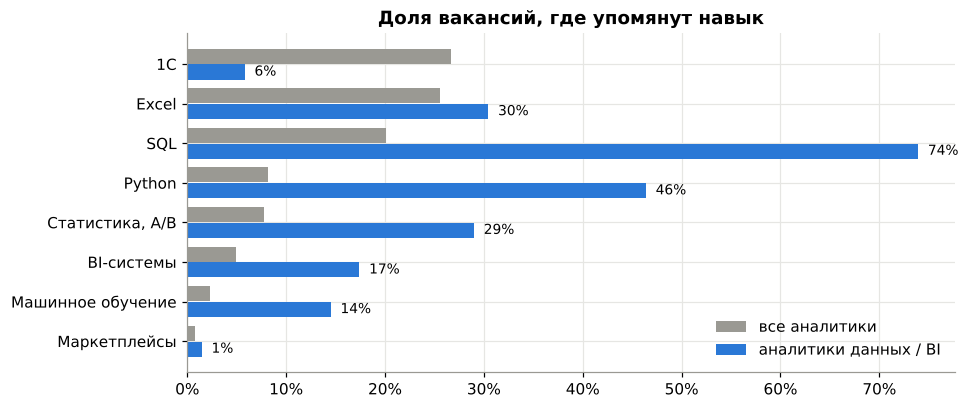

,все аналитики,аналитики данных / BI
Маркетплейсы,0.8,1.4
Машинное обучение,2.3,14.5
BI-системы,4.9,17.4
"Статистика, A/B",7.8,29.0
Python,8.1,46.4
SQL,20.1,73.9
Excel,25.6,30.4
1С,26.7,5.8


In [9]:
# Флаг BPMN в выгрузке искал и слово «требования», которое есть почти в любой вакансии, поэтому в анализ его не беру
names = {"excel": "Excel", "c1": "1С", "sql": "SQL", "stat": "Статистика, A/B",
         "python": "Python", "bi": "BI-системы", "mp": "Маркетплейсы", "ml": "Машинное обучение"}
share = pd.DataFrame({
    "все аналитики": a[list(names)].mean() * 100,
    "аналитики данных / BI": a.loc[a.role == "Аналитик данных / BI", list(names)].mean() * 100,
}).rename(index=names).sort_values("все аналитики")

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(share))
ax.barh(y + 0.2, share["все аналитики"], 0.38, color=GREY, label="все аналитики")
ax.barh(y - 0.2, share["аналитики данных / BI"], 0.38, color=BLUE, label="аналитики данных / BI")
ax.set_yticks(y, share.index); ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
for yi, v in enumerate(share["аналитики данных / BI"]):
    ax.text(v + 1, yi - 0.2, f"{v:.0f}%", va="center", fontsize=9)
ax.set_title("Доля вакансий, где упомянут навык"); ax.legend(frameon=False, loc="lower right")
plt.show()
share.round(1)

Надо помнить, что многие работодатели пишут требования коротко, и навык может подразумеваться, но не упоминаться. Поэтому доли — нижняя оценка.

## 6. Есть ли надбавка за SQL и Python

Сравниваю медианы зарплат в вакансиях с упоминанием навыка и без. Это **корреляция, а не причинность**: SQL чаще требуют в IT-компаниях и в Москве, где зарплаты выше и без него. Чтобы частично это учесть, повторяю сравнение отдельно для Москвы и регионов.

In [10]:
def premium(df, skill):
    w, wo = df.loc[df[skill], "salary"].dropna(), df.loc[~df[skill], "salary"].dropna()
    if len(w) < 8: return None
    diff = np.array([np.median(rng.choice(w, len(w))) - np.median(rng.choice(wo, len(wo))) for _ in range(4000)])
    return {"навык": names[skill], "с навыком, n": len(w), "медиана с навыком": w.median(), "медиана без": wo.median(),
            "разница": w.median() - wo.median(), "95% ДИ разницы от": np.percentile(diff, 2.5),
            "95% ДИ разницы до": np.percentile(diff, 97.5), "p (Манн — Уитни)": stats.mannwhitneyu(w, wo).pvalue}

rows = []
for scope, part in [("вся страна", a), ("Москва и область", a[a.moscow == "Москва и область"]), ("регионы", a[a.moscow == "Регионы"])]:
    for sk in ["sql", "python", "excel", "c1", "bi"]:
        res = premium(part, sk)
        if res: rows.append({"срез": scope, **res})
prem = pd.DataFrame(rows)
prem.style.format({c: "{:,.0f}" for c in ["медиана с навыком", "медиана без", "разница", "95% ДИ разницы от", "95% ДИ разницы до"]} | {"p (Манн — Уитни)": "{:.1e}"}).hide(axis="index")

срез,навык,"с навыком, n",медиана с навыком,медиана без,разница,95% ДИ разницы от,95% ДИ разницы до,p (Манн — Уитни)
вся страна,SQL,98,"110,000","62,000","48,000","35,000","64,000",3.8e-11
вся страна,Python,38,"117,500","64,717","52,783","32,250","60,912",3.1e-07
вся страна,Excel,131,"56,650","72,500","-15,850","-25,790","4,283",1.2e-01
вся страна,1С,141,"47,500","77,277","-29,777","-37,800","-18,148",7.9e-06
вся страна,BI-системы,26,"105,103","65,000","40,103","25,619","83,225",4.5e-05
Москва и область,SQL,41,"150,000","140,000","10,000","-20,000","56,800",1.1e-02
Москва и область,Python,18,"128,750","145,000","-16,250","-30,000","48,450",3.8e-01
Москва и область,Excel,27,"150,000","130,000","20,000",0,"50,000",7.1e-02
Москва и область,1С,22,"142,500","142,500",0,"-50,000","30,000",5.2e-01
Москва и область,BI-системы,14,"128,750","145,000","-16,250","-50,000","25,000",9.4e-01


**Здесь видна классическая ловушка.** По всей стране вакансии с SQL платят на ~48 тыс. ₽ больше, и разница уверенно значима. Но внутри Москвы надбавка всего ~10 тыс. ₽, и доверительный интервал включает ноль. Большая часть «эффекта SQL» объясняется тем, что SQL чаще требуют московские работодатели, которые и так платят больше. В регионах надбавка остаётся заметной: +35 тыс. ₽, и интервал выше нуля. 1С, наоборот, связан с более низкими зарплатами: это в основном региональные вакансии «аналитик-специалист».

## 7. Вакансии для начинающих

In [11]:
a["level"] = pd.cut(a.exp, [-1, 0, 1, 3, 99], labels=["без опыта", "до 1 года", "1–3 года", "больше 3 лет"])
lvl = salary_table(a, "level")
lvl["доля вакансий, %"] = lvl["вакансий"] / lvl["вакансий"].sum() * 100
lvl = lvl.set_index("level").loc[["без опыта", "до 1 года", "1–3 года", "больше 3 лет"]].reset_index()
lvl[["level", "вакансий", "доля вакансий, %", "с зарплатой", "медиана, ₽", "95% ДИ от", "95% ДИ до"]]

,level,вакансий,"доля вакансий, %",с зарплатой,"медиана, ₽",95% ДИ от,95% ДИ до
0,без опыта,96,18.2,95,47 500.0,43 349.0,55 500.0
1,до 1 года,173,32.8,173,62 584.5,55 000.0,70 579.0
2,1–3 года,189,35.8,188,77 238.5,64 433.5,90 000.0
3,больше 3 лет,70,13.3,60,125 000.0,100 000.0,155 000.0


In [12]:
junior = a[a.exp <= 1]
print(f"Вакансий для начинающих (опыт до 1 года): {len(junior)} из {len(a)} ({len(junior)/len(a):.0%})")
print("Чаще всего в них требуют:")
print((junior[list(names)].mean() * 100).rename(index=names).sort_values(ascending=False).round(1).astype(str).add("%").head(6).to_string())

Вакансий для начинающих (опыт до 1 года): 269 из 528 (51%)
Чаще всего в них требуют:
1С                 22.3%
Excel              20.4%
SQL                12.3%
Python              5.9%
Статистика, A/B     5.2%
BI-системы          3.7%


In [13]:
msk = a[a.moscow == "Москва и область"]
for label, mask in [("опыт до 1 года", msk.exp <= 1), ("опыт 1–3 года", msk.exp.between(2, 3)), ("все", msk.exp.notna() | msk.exp.isna())]:
    s_ = msk.loc[mask, "salary"].dropna()
    r_ = lambda v: f"{v:,.0f}".replace(",", " ")
    print(f"Москва и область, {label}: n = {len(s_)}, медиана {r_(s_.median())} ₽, "
          f"межквартильный размах {r_(s_.quantile(.25))}–{r_(s_.quantile(.75))} ₽")

Москва и область, опыт до 1 года: n = 40, медиана 110 000 ₽, межквартильный размах 70 250–150 000 ₽
Москва и область, опыт 1–3 года: n = 48, медиана 147 500 ₽, межквартильный размах 100 000–173 125 ₽
Москва и область, все: n = 114, медиана 142 500 ₽, межквартильный размах 95 000–175 000 ₽


## 8. Выводы

1. **Больше половины вакансий — не IT.** «Аналитик» без уточнения, аналитик 1С и финансовый аналитик — 292 из 528 вакансий (55%), медианы 41–57 тыс. ₽. Аналитики данных, системные и бизнес-аналитики получают 93–117 тыс. ₽, почти вдвое больше.
2. **Для аналитика данных SQL — обязательный минимум:** он упомянут в 74% таких вакансий, Python — в 46%, статистика и A/B — в 29%, BI-системы — в 17%. На собеседовании первым делом проверят SQL.
3. **Москва платит в 2,5 раза больше регионов** (медиана 142,5 тыс. против 57 тыс. ₽), а удалённая работа прямо указана только в 3% вакансий. Удалёнку надёжнее искать у московских работодателей и в IT-компаниях, которых больше на hh.ru.
4. **Половина вакансий доступна с опытом до года**, но зарплата растёт с опытом: 47,5 тыс. ₽ без опыта, 63 тыс. — до года, 77 тыс. — 1–3 года, 125 тыс. — больше 3 лет. Реальный опыт с бизнес-результатами стоит подавать как опыт, а не начинать «с нуля».
5. **Надбавка за SQL в основном объясняется географией:** по стране +48 тыс. ₽, внутри Москвы +10 тыс. ₽ (незначимо). Это хороший пример, почему корреляцию нельзя выдавать за причину.

**Ограничения.** Портал смещён к госсектору и регионам, навыки ищутся по тексту (часть подразумевается и не упоминается), группы по ролям небольшие, поэтому приведены доверительные интервалы. Следующий шаг — повторить анализ на данных hh.ru через официальный доступ к API.

**Как воспроизвести:** вакансии получены запросами `GET https://opendata.trudvsem.ru/api/v1/vacancies?text=аналитик&limit=100&offset=N`. Скрипт выгрузки — [`fetch_vacancies.py`](fetch_vacancies.py), сырые данные — [`data/vacancies.tsv`](data/vacancies.tsv).